# Chapter 58: Trade Policy, Integration, Tariffs, and Welfare

This notebook reruns four worked examples from the chapter: an optimal tariff for a large buyer, the Marshall-Lerner condition after a depreciation, trade creation against trade diversion, and spatial arbitrage between two markets. All examples are hypothetical, as in the book; a few extra input values are added for comparison.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def label(ax, x, y, text, col="ink", dx=6, dy=6, ha="left", va="bottom", box=True, size=LABEL_SIZE):
    """Direct label at data point (x, y) offset by (dx, dy) points, with a white box by default."""
    kw = {}
    if box:
        kw["bbox"] = {"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9}
    return ax.annotate(tex_safe(text), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                       color=color(col), fontsize=size, **kw)


def mark(ax, x, y, text=None, col="ink", size=42, dx=6, dy=6, ha="left", va="bottom", zorder=5):
    """Filled point with an optional direct label."""
    ax.scatter([x], [y], s=size, color=color(col), zorder=zorder)
    if text:
        label(ax, x, y, text, col=col, dx=dx, dy=dy, ha=ha, va=va)


def bar_compare(ax, names, values, colors=None, value_labels=None, ylabel="Value", xlabel="Item", fmt=None,
                zero_line=True):
    """Labelled vertical bars, one per name; each bar carries its value label.

    ``value_labels`` gives the text over each bar (else ``fmt(v)`` or '{:,.2f}').
    Negative bars are allowed; labels go below them.
    """
    values = [float(v) for v in values]
    colors = colors or [color(i) for i in range(len(values))]
    xs = np.arange(len(values))
    ax.bar(xs, values, color=[color(c) for c in colors], width=0.6)
    ax.set_xticks(xs, names)
    lo, hi = min(0.0, min(values)), max(0.0, max(values))
    span = (hi - lo) or 1.0
    ax.set_ylim(lo - (0.14 * span if lo < 0 else 0), hi + 0.16 * span)
    for x, v, i in zip(xs, values, range(len(values))):
        text = value_labels[i] if value_labels else (fmt(v) if fmt else f"{v:,.2f}")
        ax.annotate(text, (x, v), xytext=(0, 4 if v >= 0 else -4), textcoords="offset points", ha="center",
                    va="bottom" if v >= 0 else "top", fontsize=LABEL_SIZE, color=PALETTE["ink"])
    if zero_line and lo < 0:
        ax.axhline(0, color=PALETTE["grey"], linewidth=1)
    ax.set_ylabel(ylabel)
    ax.set_xlabel(xlabel)
    return ax


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def signed(value, digits=2, comma=True):
    """Number for use inside a written sum: negatives get parentheses, '(-5.00)'."""
    text = num(value, digits, comma)
    return f"({text})" if text.startswith("-") else text


def tariff_welfare(q0, p0, t, dq_pct, eps):
    """Large-country tariff: terms-of-trade gain minus the distortion triangle.

    optimal-tariff-argument (chapter 58): q0 = 120, p0 = 20, t = 0.125, imports fall 10 percent,
    foreign price falls 10/8 = 1.25 percent: p* = 19.75, p = 1.125(19.75) = 22.21875,
    gain 0.25(108) = 27, triangle 0.5(12)(2.46875) = 14.8125, net 12.1875.
    The quantity response dq_pct is an assumed outcome; the foreign price cut is dq_pct / eps.
    """
    cut = dq_pct / eps / 100.0
    p_star = p0 * (1.0 - cut)
    q1 = q0 * (1.0 - dq_pct / 100.0)
    p_home = (1.0 + t) * p_star
    wedge = p_home - p_star
    gain = (p0 - p_star) * q1
    loss = 0.5 * (q0 - q1) * wedge
    return {"t_star": 1.0 / eps, "cut_pct": 100.0 * cut, "p_star": p_star, "q1": q1, "p_home": p_home,
            "wedge": wedge, "tot_gain": gain, "distortion": loss, "net": gain - loss}


def trade_balance(PX, X, e, PM_star, M):
    """Trade balance in domestic currency: TB = P_X X - e P_M^* M.

    marshall-lerner-condition (chapter 58): 5(224) - 1.2 x 5 x 176 = 1,120 - 1,056 = 64.
    j-curve-effect (chapter 59): 100(10) - 1.2 x 10 x 100 = -200; 125(11) - 1.2 x 10 x 70 = 535.
    Returns a dict with exports, imports and balance.
    """
    exports = PX * X
    imports = e * PM_star * M
    return {"exports": exports, "imports": imports, "balance": exports - imports}


def midpoint_elasticity(q0, q1, p0, p1):
    """Absolute midpoint (arc) elasticity: |dq / mean q| / |dp / mean p|.

    marshall-lerner-condition (chapter 58): exports 200 to 224 as the foreign price goes 5 to
    4.1667: (24/212) / (0.8333/4.5833) = 0.62; imports 200 to 176 as the price goes 5 to 6:
    (24/188) / (1/5.5) = 0.70; sum 1.32.
    """
    dq = abs(q1 - q0) / ((q0 + q1) / 2.0)
    dp = abs(p1 - p0) / ((p0 + p1) / 2.0)
    return dq / dp


def fta_welfare(home, partner, outsider, tariff, q):
    """Home welfare change when the partner's tariff is removed, quantity fixed at q.

    trade-creation-and-trade-diversion (chapter 58). Product C: home 16, partner 12, outsider 11,
    tariff 6, 80 units: buyers move from home (16) to partner (12), saving 4(80) = 320 (creation).
    Product D: no home (home=None), outsider 9, partner 11.50, tariff 4, 120 units: buyers move
    from the outsider at 13 to the partner at 11.50, saving 180 but losing 480 revenue: -300.
    A partner price equal to the outsider's delivered price is a tie: reported, no switch.
    Returns sources and prices before and after, consumer saving, revenue loss, welfare, tie.
    """
    def best(options):
        return min(options, key=lambda kv: kv[1])
    before = [("outsider", outsider + tariff), ("partner", partner + tariff)]
    after = [("outsider", outsider + tariff)]
    if home is not None:
        before.append(("home", home))
        after.append(("home", home))
    src0, price0 = best(before)
    alt, alt_price = best(after)
    tie = abs(partner - alt_price) < 1e-12
    if partner < alt_price and not tie:
        src1, price1 = "partner", partner
    else:
        src1, price1 = (src0, price0) if src0 != "partner" else (alt, alt_price)
    rev0 = tariff * q if src0 in ("outsider", "partner") else 0.0
    rev1 = tariff * q if src1 == "outsider" else 0.0
    saving = (price0 - price1) * q
    return {"source_before": src0, "price_before": price0, "source_after": src1, "price_after": price1,
            "consumer_saving": saving, "revenue_loss": rev0 - rev1, "welfare": saving - (rev0 - rev1), "tie": tie}


def arbitrage_margin(PA, PB, costs):
    """Spatial arbitrage margin pi_AB = P_B - P_A - c_AB, with c_AB the sum of per-unit transfer costs.

    commodity-arbitrage-spatial-prices (chapter 58): c = 21 + 8 + 5 + 4 + 3 = 41;
    201 - 150 - 41 = 10; 195 - 154 - 41 = 0; with freight 15, c = 35 and 195 - 154 - 35 = 6.
    """
    c = float(sum(costs))
    return {"cost": c, "spread": PB - PA, "margin": PB - PA - c}


plt.rcParams.update(HOUSE_RC)


trade = SimpleNamespace(tariff_welfare=tariff_welfare, trade_balance=trade_balance, midpoint_elasticity=midpoint_elasticity, fta_welfare=fta_welfare, arbitrage_margin=arbitrage_margin)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'optimal-tariff-argument': {'q0': 120,
                             'p0': 20,
                             'eps': 8,
                             't': 0.125,
                             'dq_pct': 10,
                             'q1': 108,
                             'p_star': 19.75,
                             'p_home': 22.21875,
                             'tot_gain': 27,
                             'wedge': 2.46875,
                             'distortion': 14.8125,
                             'net': 12.1875},
 'marshall-lerner-condition': {'X0': 200,
                               'M0': 200,
                               'PX': 5,
                               'PM_star': 5,
                               'e1': 1.2,
                               'X1': 224,
                               'M1': 176,
                               'exports': 1120,
                               'imports': 1056,
                               'tb': 64,
                               'eps_X': 0.62,
                               'eps_M': 0.7,
                               'sum': 1.32,
                               'X1_weak': 206,
                               'M1_weak': 194,
                               'exports_weak': 1030,
                               'imports_weak': 1164,
                               'tb_weak': -134},
 'trade-creation-and-trade-diversion': {'C': {'home': 16,
                                              'partner': 12,
                                              'outsider': 11,
                                              'tariff': 6,
                                              'q': 80,
                                              'creation': 320},
                                        'D': {'partner': 11.5,
                                              'outsider': 9,
                                              'tariff': 4,
                                              'q': 120,
                                              'saving': 180,
                                              'revenue_loss': 480,
                                              'welfare': -300},
                                        'net': 20},
 'commodity-arbitrage-spatial-prices': {'PA': 150,
                                        'PB': 201,
                                        'costs': [21, 8, 5, 4, 3],
                                        'cost': 41,
                                        'margin': 10,
                                        'PA_adj': 154,
                                        'PB_adj': 195,
                                        'freight_2': 15,
                                        'cost_2': 35,
                                        'margin_2': 6,
                                        'PA_adj_2': 156,
                                        'PB_adj_2': 191},
 'constructed': {'optimal-tariff-argument': {'eps': [4, 16], 'dq_pct': [5, 20]},
                 'marshall-lerner-condition': {'x1': [215], 'm1': [185]},
                 'trade-creation-and-trade-diversion': {'p_d': [9.5, 12.5], 't_d': [2, 6]},
                 'commodity-arbitrage-spatial-prices': {'freight': [27],
                                                        'adjusted_27': [152, 199]}}}


def tariff_picture(eps=8, dq=10):
    b = BV["optimal-tariff-argument"]
    q0, p0, t = b["q0"], b["p0"], b["t"]
    r = trade.tariff_welfare(q0, p0, t, dq, eps)
    fig, ax = new_figure()
    qs = np.linspace(60, 135, 100)
    ax.plot(qs, p0 * (1 + (qs / q0 - 1) / eps), color=PALETTE["navy"], linewidth=2, label="foreign export supply")
    ax.fill_between([0, r["q1"]], r["p_star"], p0, color=PALETTE["teal"], alpha=0.55,
                    label="terms-of-trade gain")
    ax.fill([r["q1"], q0, r["q1"]], [r["p_star"], r["p_star"], r["p_home"]], color=PALETTE["terracotta"],
            alpha=0.6, label="distortion triangle")
    ax.plot([0, r["q1"]], [r["p_home"], r["p_home"]], color=PALETTE["gold"], linewidth=1.6, linestyle="dashed")
    mark(ax, q0, p0, f"free trade ({num(q0, 0)}, {num(p0)})", col="ink", dx=-6, dy=8, ha="right")
    mark(ax, r["q1"], r["p_home"], f"home price {num(r['p_home'], 4)}", col="gold", dx=-6, dy=6, ha="right")
    ax.set_xlim(0, 140)
    ax.set_ylim(15, 26)
    ax.legend(loc="lower right", frameon=False)
    ax.set_xlabel("Imports (units)")
    ax.set_ylabel("Price")
    verdict = ("the tariff pays the importing country" if r["net"] > 1e-9 else
               ("the tariff leaves the country no better off" if abs(r["net"]) <= 1e-9 else
                "the tariff costs the importing country more than it gains"))
    metrics = {"Foreign price p*": num(r["p_star"], 4), "Home price": num(r["p_home"], 5),
               "Terms-of-trade gain": num(r["tot_gain"], 4), "Distortion": num(r["distortion"], 4),
               "National gain": num(r["net"], 4), "Benchmark t* = 1/eps": num(r["t_star"], 4)}
    interp = (f"Imports fall {dq} percent to {num(r['q1'], 0)} and the foreign price falls {num(dq, 0)} / {eps} = "
              f"{num(r['cut_pct'], 4)} percent to {num(r['p_star'], 4)}. The home price is 1.125 x {num(r['p_star'], 4)} = "
              f"{num(r['p_home'], 5)}. Gain = {num(p0 - r['p_star'], 4)} x {num(r['q1'], 0)} = {num(r['tot_gain'], 4)}; "
              f"distortion = 0.5 x {num(q0 - r['q1'], 0)} x {num(r['wedge'], 5)} = {num(r['distortion'], 4)}; national "
              f"gain = {num(r['tot_gain'], 4)} - {num(r['distortion'], 4)} = {num(r['net'], 4)}, so {verdict}.")
    steps = [f"p* = 20 x (1 - {num(r['cut_pct'], 4)}%) = {num(r['p_star'], 4)}",
             f"Home price = 1.125 x {num(r['p_star'], 4)} = {num(r['p_home'], 5)}",
             f"Gain = {num(p0 - r['p_star'], 4)} x {num(r['q1'], 0)} = {num(r['tot_gain'], 4)}",
             f"Distortion = 0.5 x {num(q0 - r['q1'], 0)} x {num(r['wedge'], 5)} = {num(r['distortion'], 4)}",
             f"Net = {num(r['tot_gain'], 4)} - {num(r['distortion'], 4)} = {num(r['net'], 4)}"]
    alt = (f"Import market with the foreign supply curve. A 12.5 percent tariff cuts imports to {num(r['q1'], 0)} and "
           f"the foreign price to {num(r['p_star'], 4)}; the gain rectangle is {num(r['tot_gain'], 4)} and the "
           f"distortion triangle {num(r['distortion'], 4)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def _mid(a, b):
    """Midpoint of two volumes, with one decimal when it is not whole (207.5, not 208)."""
    m = (a + b) / 2
    return num(m, 0) if m == int(m) else num(m, 1)


def ml_picture(x1=224, m1=176):
    b = BV["marshall-lerner-condition"]
    PX, PM, e1 = b["PX"], b["PM_star"], b["e1"]
    before = trade.trade_balance(PX, 200, 1.0, PM, 200)
    after = trade.trade_balance(PX, x1, e1, PM, m1)
    ex = trade.midpoint_elasticity(200, x1, PX, PX / e1)
    em = trade.midpoint_elasticity(200, m1, PM, PM * e1)
    tb = after["balance"]
    fig, ax = new_figure()
    xs = np.arange(2)
    w = 0.36
    exps, imps = [before["exports"], after["exports"]], [before["imports"], after["imports"]]
    ax.bar(xs - w / 2, exps, width=w, color=PALETTE["teal"], label="export receipts")
    ax.bar(xs + w / 2, imps, width=w, color=PALETTE["gold"], label="import spending")
    for x, a, c in zip(xs, exps, imps):
        label(ax, x - w / 2, a, num(a, 0), dx=0, dy=3, ha="center")
        label(ax, x + w / 2, c, num(c, 0), dx=0, dy=3, ha="center")
    ax.set_xticks(xs, ["Before (e = 1)", f"After (e = 1.20), TB = {num(tb, 0)}"])
    ax.set_ylim(0, 1550)
    ax.legend(loc="upper left", frameon=False)
    ax.set_ylabel("Domestic currency")
    ax.set_xlabel("Trade flows")
    word = "surplus" if tb > 0 else ("deficit" if tb < 0 else "balance")
    metrics = {"Export receipts": num(after["exports"], 0), "Import spending": num(after["imports"], 0),
               "Trade balance": num(tb, 0), "eps_X": num(ex), "eps_M": num(em), "eps_X + eps_M": num(ex + em)}
    interp = (f"Exports earn 5 x {x1} = {num(after['exports'], 0)}; imports cost 1.20 x 5 x {m1} = 6 x {m1} = "
              f"{num(after['imports'], 0)}, so TB = {num(after['exports'], 0)} - {num(after['imports'], 0)} = "
              f"{num(tb, 0)}, a {word}" + ("" if tb else " of zero") + f". Midpoint elasticities are {num(ex)} and "
              f"{num(em)}, summing to {num(ex + em)}.")
    steps = [f"P_X X = 5 x {x1} = {num(after['exports'], 0)}",
             f"e P_M* M = 6 x {m1} = {num(after['imports'], 0)}",
             f"TB = {num(after['exports'], 0)} - {num(after['imports'], 0)} = {num(tb, 0)}",
             f"eps_X = ({abs(x1 - 200)} / {_mid(200, x1)}) / (0.8333 / 4.5833) = {num(ex)}",
             f"eps_M = ({abs(200 - m1)} / {_mid(200, m1)}) / (1 / 5.5) = {num(em)}"]
    alt = (f"Bars of export receipts and import spending: 1,000 each before; {num(after['exports'], 0)} and "
           f"{num(after['imports'], 0)} after the depreciation, a trade balance of {num(tb, 0)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def fta_picture(p_d=11.5, t_d=4):
    b = BV["trade-creation-and-trade-diversion"]
    c = b["C"]
    rc = trade.fta_welfare(c["home"], c["partner"], c["outsider"], c["tariff"], c["q"])
    rd = trade.fta_welfare(None, p_d, 9, t_d, 120)
    net = rc["welfare"] + rd["welfare"]
    fig, ax = new_figure()
    vals = [rc["welfare"], rd["consumer_saving"], -rd["revenue_loss"], rd["welfare"], net]
    names = ["C creation", "D buyer saving", "D lost revenue", "D net", "Total"]
    bar_compare(ax, names, vals, colors=["teal", "gold", "terracotta", "navy", "ink"],
                value_labels=[num(v, 0) for v in vals], ylabel="Home welfare change", xlabel="Free trade agreement")
    ax.set_ylim(-850, 820)
    switched = rd["source_after"] == "partner"
    outsider_price = 9 + t_d
    if rd["tie"]:
        d_text = (f"Partner cost {num(p_d)} ties the outsider's delivered {num(outsider_price)}: buyers have no reason "
                  f"to switch, and D's change is 0.")
    elif switched:
        d_text = (f"In D the partner's {num(p_d)} beats the outsider's delivered 9 + {num(t_d, 0)} = {num(outsider_price)}, "
                  f"so buyers switch: saving ({num(outsider_price)} - {num(p_d)}) x 120 = {num(rd['consumer_saving'], 0)}, "
                  f"lost revenue {num(t_d, 0)} x 120 = {num(rd['revenue_loss'], 0)}, net {num(rd['welfare'], 0)}.")
    else:
        d_text = (f"In D the partner's {num(p_d)} is above the outsider's delivered 9 + {num(t_d, 0)} = "
                  f"{num(outsider_price)}, so buyers stay with the outsider and D's change is 0.")
    metrics = {"Creation (C)": num(rc["welfare"], 0), "D buyers switch": "yes" if switched else "no",
               "D welfare change": num(rd["welfare"], 0), "Net welfare": num(net, 0)}
    interp = (f"In C buyers move from home output at 16 to the partner at 12: (16 - 12) x 80 = {num(rc['welfare'], 0)}. "
              f"{d_text} Net: {num(rc['welfare'], 0)} + {signed(rd['welfare'], 0)} = {num(net, 0)}.")
    steps = [f"C: 16 x 80 - 12 x 80 = 1,280 - 960 = {num(rc['welfare'], 0)}",
             f"D: outsider delivered 9 + {num(t_d, 0)} = {num(outsider_price)}; partner {num(p_d)}",
             (f"D: {num(rd['consumer_saving'], 0)} - {num(rd['revenue_loss'], 0)} = {num(rd['welfare'], 0)}" if switched
              else "D: no switch, change 0"),
             f"Net = {num(rc['welfare'], 0)} + {signed(rd['welfare'], 0)} = {num(net, 0)}"]
    alt = (f"Bars: creation in C {num(rc['welfare'], 0)}, D buyer saving {num(rd['consumer_saving'], 0)}, D lost "
           f"revenue {num(-rd['revenue_loss'], 0)}, D net {num(rd['welfare'], 0)}, total {num(net, 0)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def arbitrage_picture(freight=21, stage="before"):
    b = BV["commodity-arbitrage-spatial-prices"]
    adjusted = {15: (156, 191), 21: (154, 195), 27: (152, 199)}  # book: 154/195 and 156/191; 152/199 constructed
    costs = [freight] + b["costs"][1:]
    PA, PB = (b["PA"], b["PB"]) if stage == "before" else adjusted[freight]
    r = trade.arbitrage_margin(PA, PB, costs)
    fig, ax = new_figure()
    ax.fill_between([0.3, 0.7], PA, PA + r["cost"], color=PALETTE["light"], label="transfer cost band")
    if r["margin"] > 0:
        ax.fill_between([0.3, 0.7], PA + r["cost"], PB, color=PALETTE["teal"], alpha=0.6, label="arbitrage margin")
    mark(ax, 0.5, PA, f"P_A = {num(PA, 0)}", col="navy", dx=60, dy=-4, va="top")
    mark(ax, 0.5, PB, f"P_B = {num(PB, 0)}", col="terracotta", dx=60, dy=4)
    ax.set_xlim(0, 1.6)
    ax.set_xticks([])
    ax.set_ylim(130, 215)
    ax.legend(loc="lower right", frameon=False)
    ax.set_ylabel("Price per unit")
    ax.set_xlabel("Harbor A to City B")
    metrics = {"Transfer cost": num(r["cost"], 0), "Price spread": num(r["spread"], 0), "Margin": num(r["margin"], 0)}
    sums = " + ".join(str(c) for c in costs)
    tail = ("Traders keep shipping until the margin closes." if r["margin"] > 0 else
            "The margin is zero: prices stay apart by exactly the transfer cost.")
    interp = (f"c = {sums} = {num(r['cost'], 0)}. Margin = {num(PB, 0)} - {num(PA, 0)} - {num(r['cost'], 0)} = "
              f"{num(r['margin'], 0)}. {tail}")
    steps = [f"c = {sums} = {num(r['cost'], 0)}", f"Spread = {num(PB, 0)} - {num(PA, 0)} = {num(r['spread'], 0)}",
             f"Margin = {num(r['spread'], 0)} - {num(r['cost'], 0)} = {num(r['margin'], 0)}"]
    alt = (f"Price in A {num(PA, 0)} and in B {num(PB, 0)}, with a transfer cost band of {num(r['cost'], 0)}; the "
           f"margin is {num(r['margin'], 0)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Optimal-tariff argument: a tariff that pays the large buyer

Imports are 120 units at a foreign price of 20 and foreign export supply has elasticity 8:

$$t^*=\frac{1}{8}=0.125$$

Imports fall 10 percent to 108 and the foreign price falls 1.25 percent to 19.75:

$$p=1.125(19.75)=22.21875, \qquad 0.25(108)=27, \qquad \frac{1}{2}(12)(2.46875)=14.8125$$

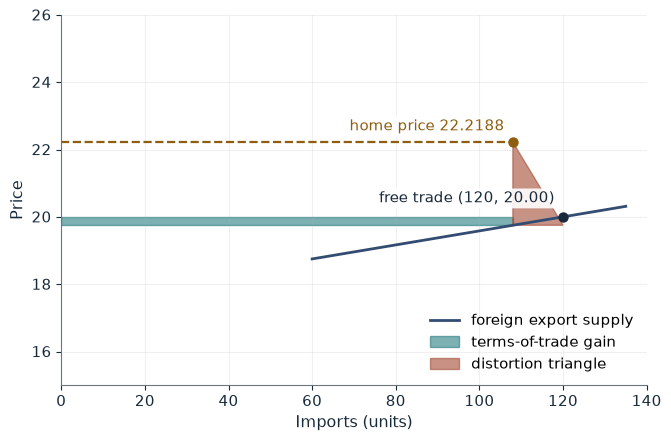

Foreign price p*      19.7500
Home price            22.21875
Terms-of-trade gain   27.0000
Distortion            14.8125
National gain         12.1875
Benchmark t* = 1/eps  0.1250

Worked steps:
  1. p* = 20 x (1 - 1.2500%) = 19.7500
  2. Home price = 1.125 x 19.7500 = 22.21875
  3. Gain = 0.2500 x 108 = 27.0000
  4. Distortion = 0.5 x 12 x 2.46875 = 14.8125
  5. Net = 27.0000 - 14.8125 = 12.1875

Imports fall 10 percent to 108 and the foreign price falls 10 / 8 = 1.2500 percent to 19.7500. The home price is 1.125 x 19.7500 = 22.21875. Gain = 0.2500 x 108 = 27.0000; distortion = 0.5 x 12 x 2.46875 = 14.8125; national gain = 27.0000 - 14.8125 = 12.1875, so the tariff pays the importing country.


In [2]:
show(tariff_picture(eps=8, dq=10))

Change one input, `eps`, and hold the others at the book's values:

In [3]:
sweep(tariff_picture, 'eps', [4, 8, 16], {'dq': 10}, ['Foreign price p*', 'Terms-of-trade gain', 'Distortion', 'National gain'])

eps | Foreign price p* | Terms-of-trade gain | Distortion | National gain
4 | 19.5000 | 54.0000 | 14.6250 | 39.3750
8 | 19.7500 | 27.0000 | 14.8125 | 12.1875
16 | 19.8750 | 13.5000 | 14.9062 | -1.4062


The gain of 27 beats the distortion of 14.8125, a national gain of 12.1875. With elastic foreign supply (eps = 16) the foreign price barely moves and the same tariff loses 1.41.

## 2. Marshall-Lerner condition: when depreciation improves the trade balance

Exports and imports are 200 units at 5; the currency depreciates from $e=1$ to $e=1.20$. With export volume 224 and import volume 176:

$$P_XX=5(224)=1{,}120, \qquad eP_M^*M=6(176)=1{,}056$$

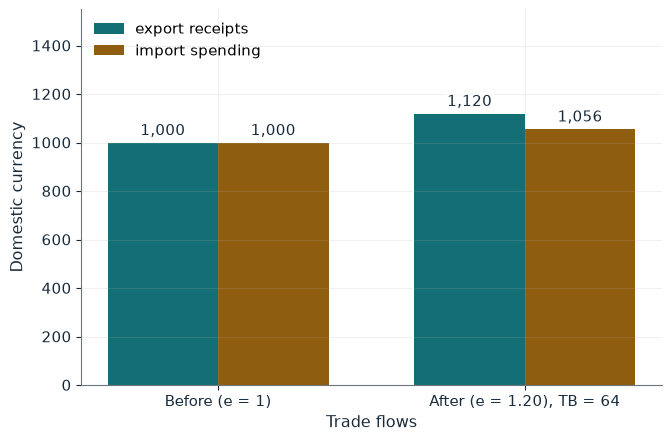

Export receipts  1,120
Import spending  1,056
Trade balance    64
eps_X            0.62
eps_M            0.70
eps_X + eps_M    1.32

Worked steps:
  1. P_X X = 5 x 224 = 1,120
  2. e P_M* M = 6 x 176 = 1,056
  3. TB = 1,120 - 1,056 = 64
  4. eps_X = (24 / 212) / (0.8333 / 4.5833) = 0.62
  5. eps_M = (24 / 188) / (1 / 5.5) = 0.70

Exports earn 5 x 224 = 1,120; imports cost 1.20 x 5 x 176 = 6 x 176 = 1,056, so TB = 1,120 - 1,056 = 64, a surplus. Midpoint elasticities are 0.62 and 0.70, summing to 1.32.


In [4]:
show(ml_picture(x1=224, m1=176))

Change one input, `x1`, and hold the others at the book's values:

In [5]:
sweep(ml_picture, 'x1', [206, 215, 224], {'m1': 194}, ['Trade balance', 'eps_X + eps_M'])

x1 | Trade balance | eps_X + eps_M
206 | -134 | 0.33
215 | -89 | 0.57
224 | -44 | 0.79


At the book's volumes the balance is a surplus of 64 and the elasticities sum to 1.32. With the weak responses 206 and 194 the balance is a deficit of 134.

## 3. Trade creation and trade diversion

Product C moves from home output at 16 to the partner at 12 on 80 units; product D moves from the outsider (9 plus a tariff of 4) to the partner at 11.50 on 120 units:

$$12(80)=960, \qquad (13-11.50)(120)=180$$

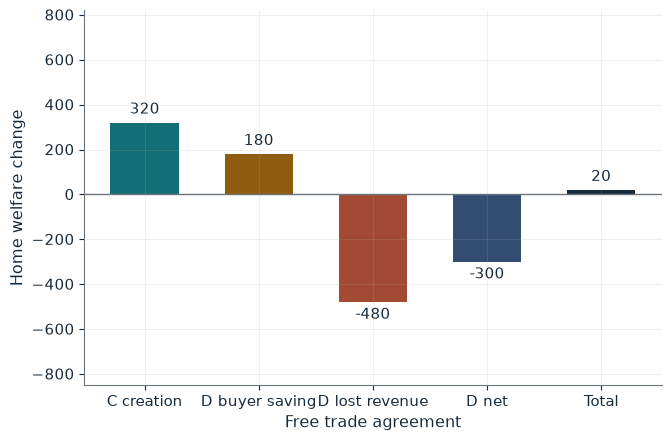

Creation (C)      320
D buyers switch   yes
D welfare change  -300
Net welfare       20

Worked steps:
  1. C: 16 x 80 - 12 x 80 = 1,280 - 960 = 320
  2. D: outsider delivered 9 + 4 = 13.00; partner 11.50
  3. D: 180 - 480 = -300
  4. Net = 320 + (-300) = 20

In C buyers move from home output at 16 to the partner at 12: (16 - 12) x 80 = 320. In D the partner's 11.50 beats the outsider's delivered 9 + 4 = 13.00, so buyers switch: saving (13.00 - 11.50) x 120 = 180, lost revenue 4 x 120 = 480, net -300. Net: 320 + (-300) = 20.


In [6]:
show(fta_picture(p_d=11.5, t_d=4))

Change one input, `p_d`, and hold the others at the book's values:

In [7]:
sweep(fta_picture, 'p_d', [9.5, 11.5, 12.5], {'t_d': 4}, ['D buyers switch', 'D welfare change', 'Net welfare'])

p_d | D buyers switch | D welfare change | Net welfare
9.5 | yes | -60 | 260
11.5 | yes | -300 | 20
12.5 | yes | -420 | -100


Creation in C is 320 and diversion in D costs 180 - 480 = -300, a net of 20. A dearer partner (12.50) still attracts buyers but turns the total negative.

## 4. Commodity arbitrage: prices apart by the cost of moving goods

Prices are 150 in Harbor A and 201 in City B:

$$c_{AB}=21+8+5+4+3=41, \qquad \pi_{AB}=201-150-41=10$$

A harbor project cuts freight to 15: $15+8+5+4+3=35$.

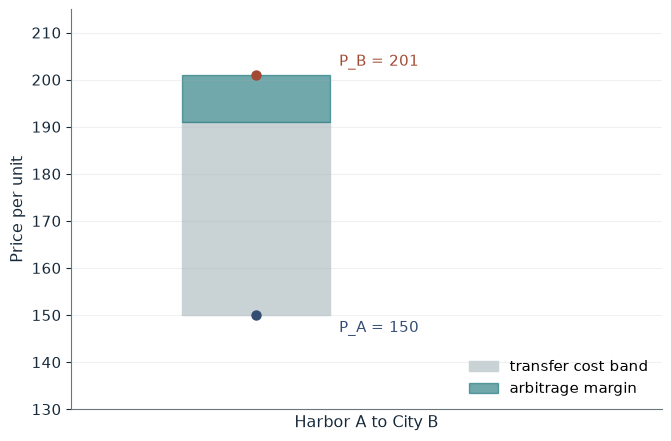

Transfer cost  41
Price spread   51
Margin         10

Worked steps:
  1. c = 21 + 8 + 5 + 4 + 3 = 41
  2. Spread = 201 - 150 = 51
  3. Margin = 51 - 41 = 10

c = 21 + 8 + 5 + 4 + 3 = 41. Margin = 201 - 150 - 41 = 10. Traders keep shipping until the margin closes.


In [8]:
show(arbitrage_picture(freight=21, stage='before'))

Change one input, `freight`, and hold the others at the book's values:

In [9]:
sweep(arbitrage_picture, 'freight', [15, 21, 27], {'stage': 'after'}, ['Transfer cost', 'Price spread', 'Margin'])

freight | Transfer cost | Price spread | Margin
15 | 35 | 35 | 0
21 | 41 | 41 | 0
27 | 47 | 47 | 0


Before traders enter the margin is 10. After adjustment the spread equals the transfer cost and the margin is zero; cheaper freight narrows the spread from 41 to 35, not to zero.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

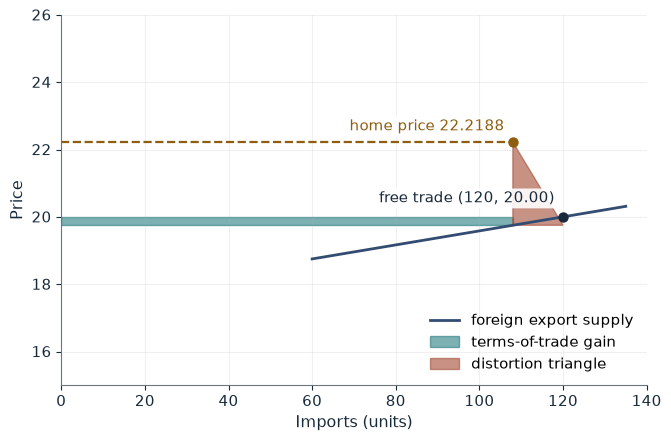

Foreign price p*      19.7500
Home price            22.21875
Terms-of-trade gain   27.0000
Distortion            14.8125
National gain         12.1875
Benchmark t* = 1/eps  0.1250

Worked steps:
  1. p* = 20 x (1 - 1.2500%) = 19.7500
  2. Home price = 1.125 x 19.7500 = 22.21875
  3. Gain = 0.2500 x 108 = 27.0000
  4. Distortion = 0.5 x 12 x 2.46875 = 14.8125
  5. Net = 27.0000 - 14.8125 = 12.1875

Imports fall 10 percent to 108 and the foreign price falls 10 / 8 = 1.2500 percent to 19.7500. The home price is 1.125 x 19.7500 = 22.21875. Gain = 0.2500 x 108 = 27.0000; distortion = 0.5 x 12 x 2.46875 = 14.8125; national gain = 27.0000 - 14.8125 = 12.1875, so the tariff pays the importing country.


In [10]:
show(tariff_picture(eps=8, dq=10))

## Practice

**1.** With eps = 16 and a 10 percent import contraction, what is the national gain from the 12.5 percent tariff?

<details><summary>Answer</summary>

p* = 19.875; gain 0.125 x 108 = 13.5; wedge 0.125 x 19.875 = 2.484375; triangle 0.5 x 12 x 2.484375 = 14.906; net 13.5 - 14.906 = -1.41.

</details>

**2.** With 206 exports and 194 imports after the depreciation, what is the trade balance?

<details><summary>Answer</summary>

5 x 206 - 6 x 194 = 1,030 - 1,164 = -134.

</details>

**3.** With freight 15, what is the arbitrage margin at prices 154 and 195?

<details><summary>Answer</summary>

c = 15 + 8 + 5 + 4 + 3 = 35, so 195 - 154 - 35 = 6.

</details>